# S&P 500 (daily): data and MGD model
Data: the 6062 daily log-returns $X(u) = \log P(u) - \log P(u-1)$ of the S&P 500, standardized once; the whole series is **one** sample ($d = 6062$).
Model: run `snp_M1` (scalar wavelet marginals and scattering moments of order 1 to 4, no $L^6$ term, $J = 6$, $Q = 1$, Morlet, periodic boundaries), 5 seeds (900–904), 100 generated series per seed, $\sigma = 3.5$.
$\Theta$ = $\Theta_{\rm reg}$ at the last time step ($t \approx 1$), unconstrained, $\lambda$ = cross-seed choice (`snp_xseed.sh`, window `end0.99`).

Run on Jean Zay from `snp_experiment/`. Needs `figures/logp_snp/logp_snp_M1.npz` (`python snp_experiment/logp_snp.py`). Figures: `figures/talk/`.

Error bands. **Data**: standard error over the 23 blocks of 256 days (value computed on the whole series). **Model**: mean over the 100 series of each seed, then mean ± std over the 5 seeds.

In [6]:
%matplotlib inline
import sys
from pathlib import Path
ROOT = Path.cwd()                                   # snp_experiment/
for p in ('codes', 'codes/filters', 'codes/potentials', 'data', 'turbulence', 'jets', 'snp_experiment'):
    sys.path.insert(0, str(ROOT.parent / p))
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
import talk_figures as tf
import run_comparison as rc
import jets_compare as jc
import snp_stats as ss
from snp_loader import load_snp_returns
from logp_family_contrib import load_potentials, phi_matrix
tf.set_output(ROOT / 'figures' / 'talk')          # every figure is also saved here as PNG

In [ ]:
LABEL, SEEDS, WINDOW = 'snp_M1', [900, 901, 902, 903, 904], 'end0.99'
configs = jc.find_seed_configs(ROOT, LABEL, SEEDS)
assert all(configs.values()), configs
runs = {s: rc.load_config(c, ROOT, label=LABEL, extras=False) for s, c in configs.items()}
cfg = runs[SEEDS[0]]['cfg']
x1, raw, dates = load_snp_returns()
x1 = x1.reshape(1, -1).numpy()                                        # data, (1, 6062), standardized
xts = [r['xt'].numpy() for r in runs.values()]                        # generated, one (100, 6062) array per seed
xt = xts[0]
xsel = torch.load(ROOT / 'results' / 'xseed' / f'xseed_{LABEL}.pt', map_location='cpu', weights_only=False)
LAM = xsel['selected'][WINDOW]
sol = torch.load(xsel['theta_files'][WINDOW][configs[SEEDS[0]]], map_location='cpu', weights_only=False)
assert sol['config'] == configs[SEEDS[0]] and float(sol['lam']) == float(LAM)
theta = sol['Theta_reg'][-1].double().numpy()
print('no L_6 term: unconstrained Theta_reg')
print('data', x1.shape, f'({dates[0].date()} to {dates[-1].date()}) | generated', xt.shape, '| seeds', SEEDS, '| lambda', LAM)

## Data and generated series
Daily log-returns (standardized): the data (top) and three generated series. Volatility clustering and the large negative days are the features to compare.

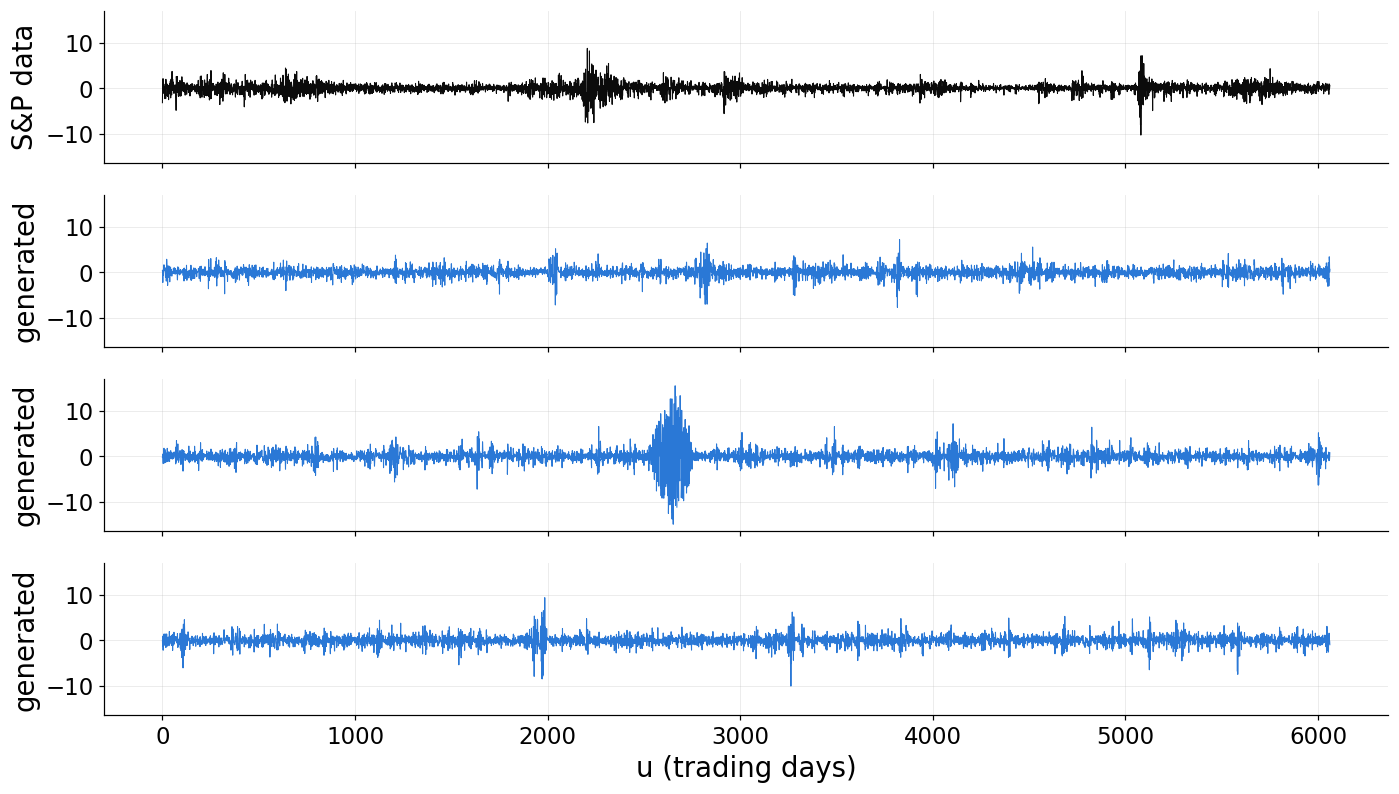

In [24]:
rng = np.random.default_rng(0)
idx = rng.choice(len(xt), 3, replace=False)
fig, axes = plt.subplots(4, 1, figsize=(13, 7.5), sharex=True, sharey=True)
axes[0].plot(x1[0], color=tf.DATA, lw=0.7); axes[0].set_ylabel('S&P data')
for ax, i in zip(axes[1:], idx):
    ax.plot(xt[i], color=tf.MODEL, lw=0.7); ax.set_ylabel('generated')
axes[-1].set_xlabel('u (trading days)')
fig.tight_layout(); tf._save(fig, 'series_data_vs_generated')

## Wavelet coefficients of the data, per scale
Histogram of the real part of the Morlet coefficients (Q = 1, J = 6) of the data; dashed: Gaussian.

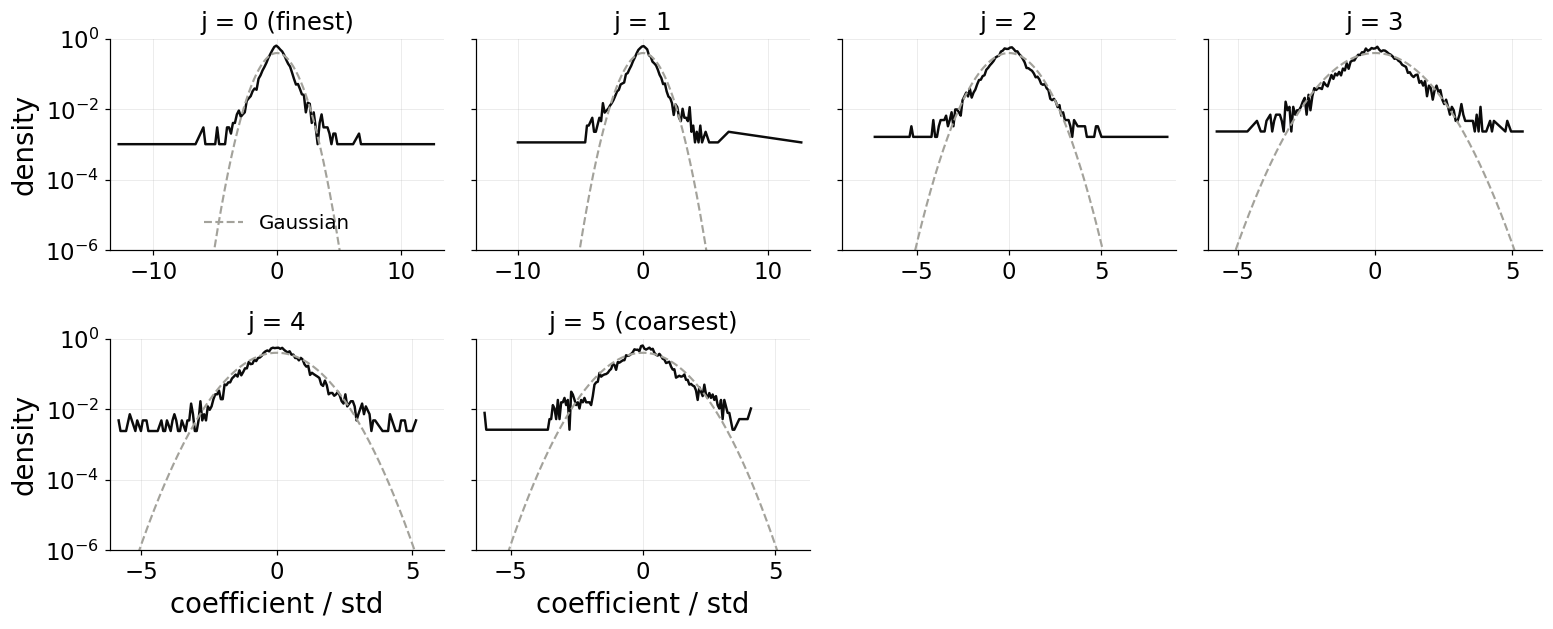

In [25]:
tf.plot_wavelet_histograms(x1, int(cfg['J']), 'data_wavelet_histograms')

## Wavelet coefficients: data vs generated
Same histograms for the 100 series of seed 900 (blue) against the data (black), pooled over the scales' coefficients of each series.

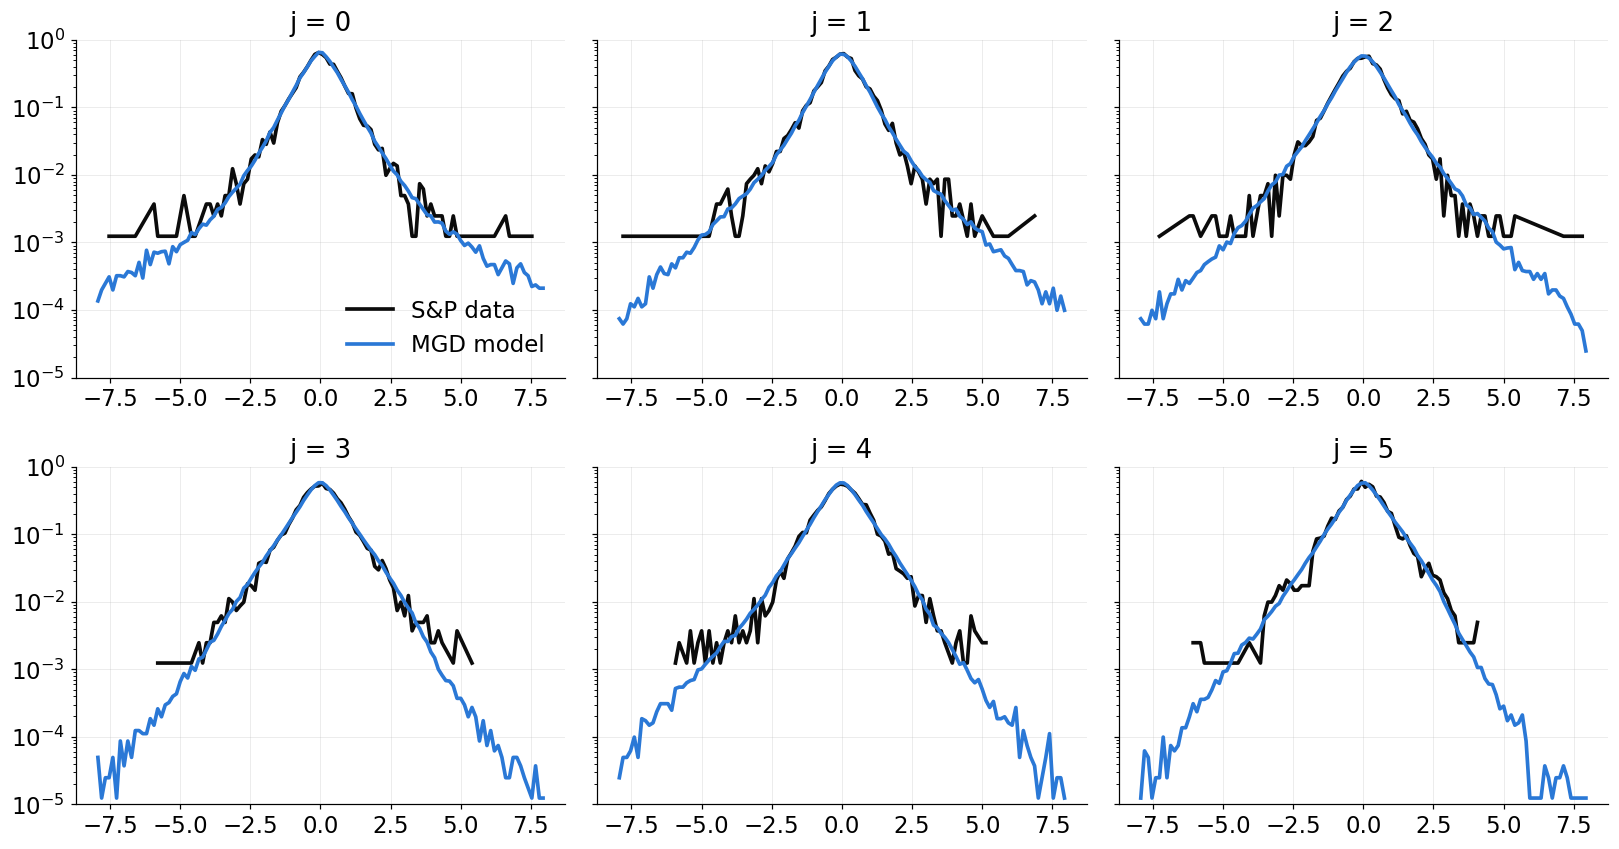

In [26]:
from filters_bank import return_Filters
J, M = int(cfg['J']), x1.shape[-1]
Fl = return_Filters(M, J, 1, device='cpu').reshape(-1, M).to(torch.complex128)[:-1]
def coefs(x):
    z = torch.fft.ifft(torch.fft.fft(torch.as_tensor(x))[:, None, :] * Fl[None], dim=-1).real.numpy()
    return z                                                                     # (n, J, M)
zd, zg = coefs(x1.astype(np.float64)), coefs(xt.astype(np.float64))
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for j, ax in enumerate(axes.flat):
    sd = zd[:, j].std()
    bins = np.linspace(-8, 8, 121)
    hd, _ = np.histogram(zd[:, j].ravel() / sd, bins, density=True)
    hg, _ = np.histogram(zg[:, j].ravel() / sd, bins, density=True)
    c = 0.5 * (bins[1:] + bins[:-1])
    ax.plot(c[hd > 0], hd[hd > 0], color=tf.DATA, label='S&P data'); ax.plot(c[hg > 0], hg[hg > 0], color=tf.MODEL, label='MGD model')
    ax.set_yscale('log'); ax.set_ylim(1e-5, 1); ax.set_title(f'j = {j}')
axes[0, 0].legend(); fig.tight_layout(); tf._save(fig, 'wavelet_histograms_data_vs_generated')

## Statistics of the S&P returns: data and model
Computed once (`snp_stats.compute`): CDF of $X$, $\mathrm{Ave}_u|\delta_s p(u)|^q$ with $\delta_s p(u) = X(u-s+1)+\dots+X(u)$ at $s = 2^j$ days, signed leverage, Zumbach moment, 5-day rolling volatility, power spectra (returns and volatility).

In [11]:
S = ss.compute(x1, xts)

  cdf: 240 points, data blocks 23 x 480, model seeds 5


/lustre/fshomisc/sup/pub/miniforge/24.11.3/envs/pytorch-gpu-2.8.0+py3.12.11/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


  inc1: 9 points, data blocks 23 x 9, model seeds 5
  inc2: 9 points, data blocks 23 x 9, model seeds 5
  inc4: 9 points, data blocks 23 x 9, model seeds 5


/lustre/fshomisc/sup/pub/miniforge/24.11.3/envs/pytorch-gpu-2.8.0+py3.12.11/lib/python3.12/site-packages/numpy/_core/_methods.py:223: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/lustre/fshomisc/sup/pub/miniforge/24.11.3/envs/pytorch-gpu-2.8.0+py3.12.11/lib/python3.12/site-packages/numpy/_core/_methods.py:212: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


  leverage: 119 points, data blocks 23 x 119, model seeds 5
  zumbach: 119 points, data blocks 23 x 119, model seeds 5
  vol5: 60 points, data blocks 23 x 60, model seeds 5


/lustre/fswork/projects/rech/wbg/ukv59en/MGD-for-Maximum-Entropy-Generation/snp_experiment/snp_stats.py:113: RuntimeWarning: Mean of empty slice
  per_seed = np.stack([np.nanmean(f(np.asarray(s, dtype=np.float64))[1], axis=0) for s in xts])
/lustre/fswork/projects/rech/wbg/ukv59en/MGD-for-Maximum-Entropy-Generation/snp_experiment/snp_stats.py:116: RuntimeWarning: Mean of empty slice
  model=np.nanmean(per_seed, axis=0), model_err=np.nanstd(per_seed, axis=0, ddof=1))


  spec_ret: 24 points, data blocks 23 x 24, model seeds 5
  spec_vol: 24 points, data blocks 23 x 24, model seeds 5


### Distribution of the returns
Both tails of the CDF of $X$ in log scale.

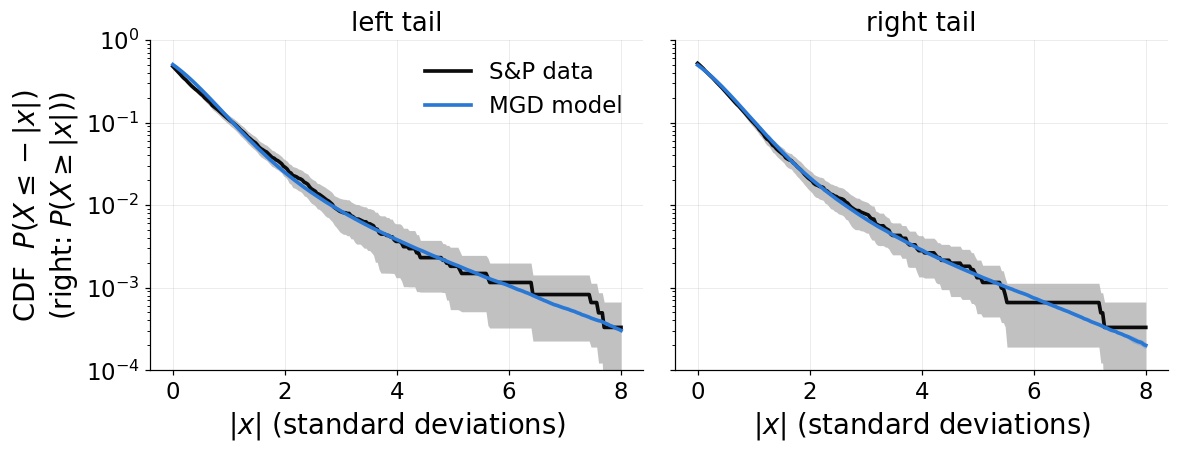

In [12]:
ss.plot_cdf(S['cdf'], 'sp_cdf')

### Increments over $s = 2^j$ days: $\mathrm{Ave}_u |\delta_s p(u)|^q$
Orders $q = 1, 2, 4$. Blocks of 256 days reach $s \le 64$ only: the data band stops there.

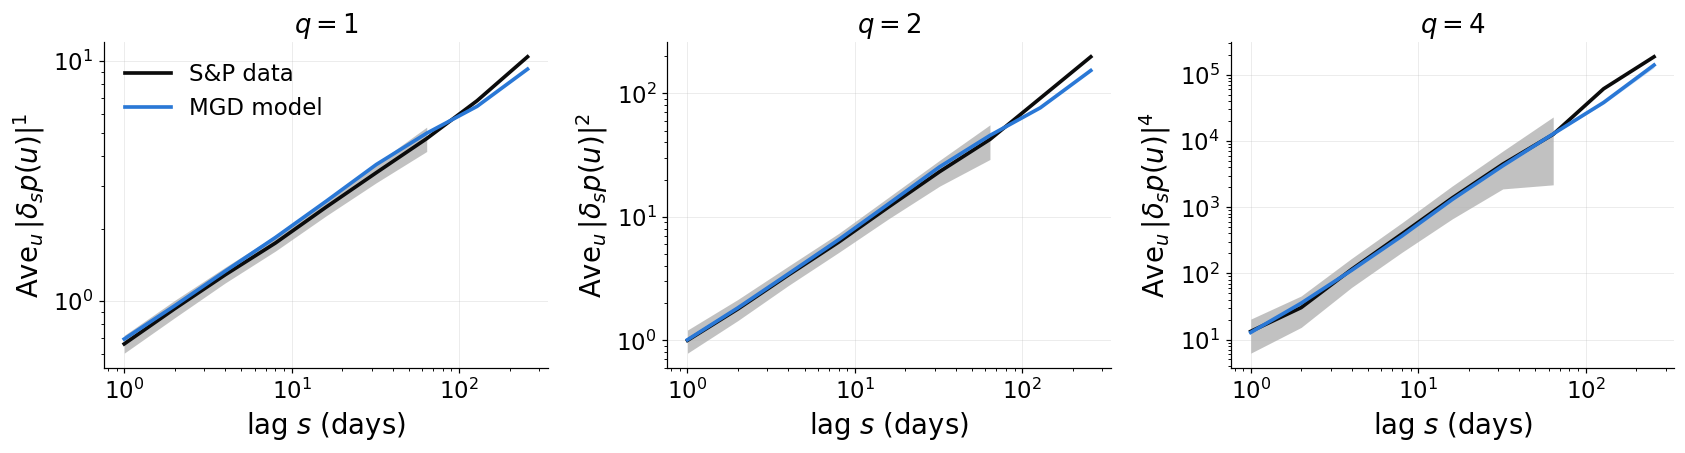

In [13]:
ss.plot_increments({1.0: S['inc1'], 2.0: S['inc2'], 4.0: S['inc4']}, 'sp_increments')

### Leverage and Zumbach
Signed leverage $L(\tau) = \langle X(t-\tau) X(t)^2 \rangle / \langle X^2 \rangle^2$: negative for $\tau > 0$ in the data (a loss today raises tomorrow's volatility). Zumbach: past 5-day squared move against present volatility; time-reversible series are symmetric in $\tau$.

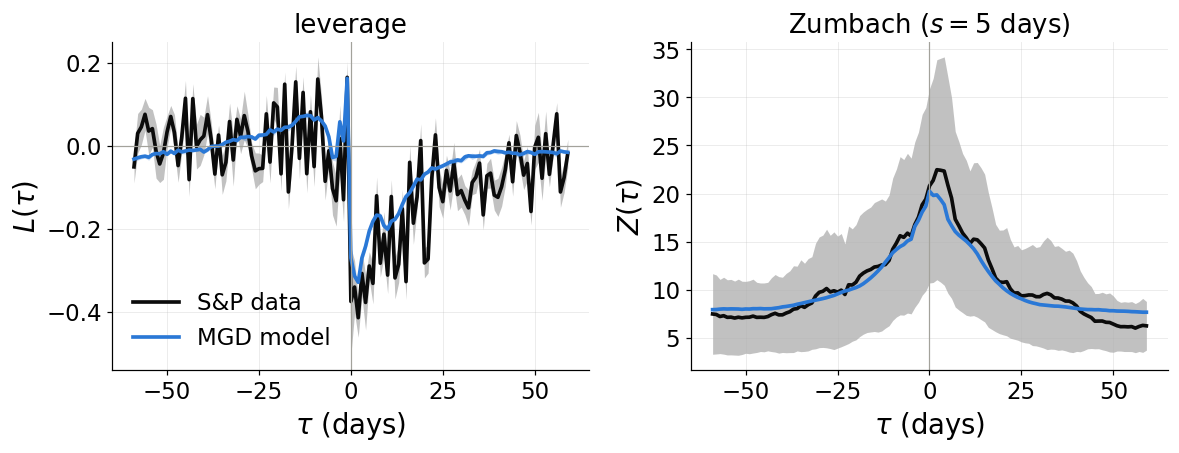

In [14]:
ss.plot_leverage_zumbach(S['leverage'], S['zumbach'], 'sp_leverage_zumbach', scale=5)

### 5-day rolling volatility
Histogram of $\log_{10}\sqrt{\frac15\sum_{5\,\rm days} X^2}$.

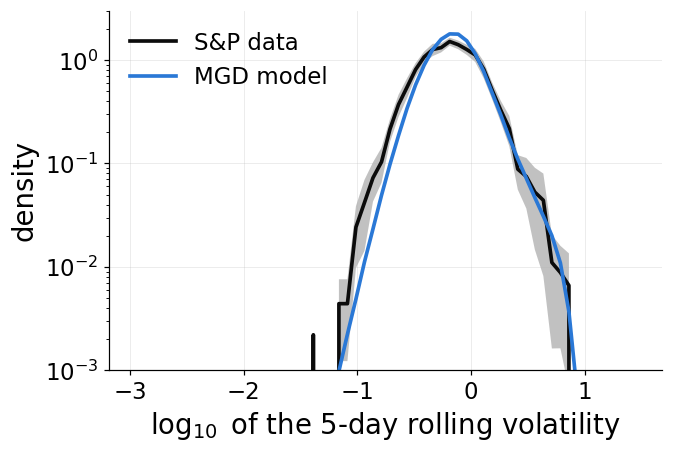

In [15]:
ss.plot_rolling_vol(S['vol5'], 'sp_rolling_vol')

### Power spectra
Returns: flat for white noise. Volatility ($|X| - \langle|X|\rangle$): long memory shows as a power law at low frequency. Data bands stop at $f = 1/256$.

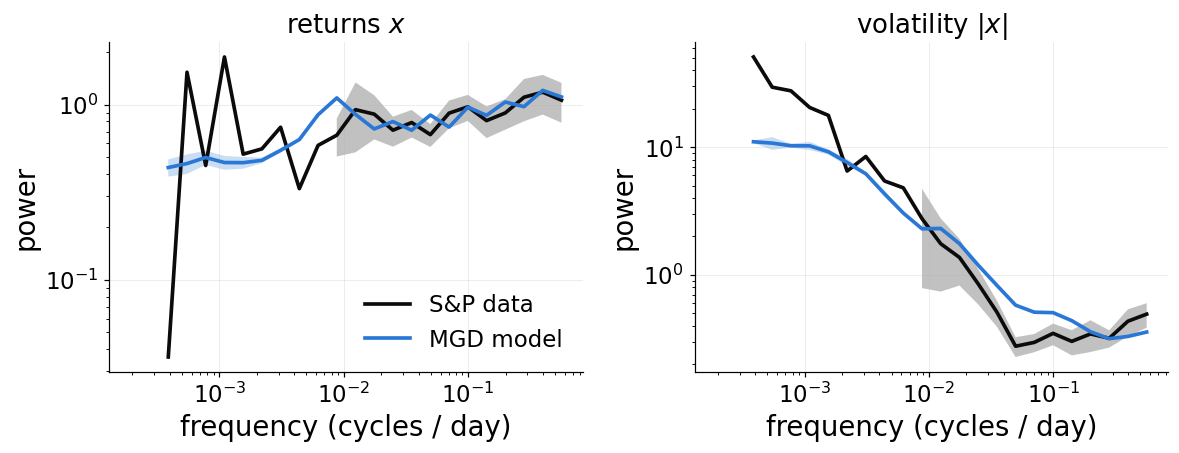

In [16]:
ss.plot_spectra(S['spec_ret'], S['spec_vol'], 'sp_spectra')

## Distribution of −log p of the generated series
$-\log_{10} p(x)/d$ with $d = 6062$, $-\log p(x) = -\Theta\cdot\phi(x)$ + constant, evaluated on the 5 × 100 generated series (histogram, unit area) and on the data (vertical line); the constant is arbitrary, so values are centred at zero by the mean of the generated ones (per seed).

In [ ]:
D = np.load(ROOT / 'figures' / 'logp_snp' / 'logp_snp_M1.npz')
assert [int(s) for s in D['seeds']] == SEEDS and abs(float(D['lam']) - LAM) < 1e-12
Cg, Cd = D['C_gen'], D['C_data']                      # (seeds, families + total, n_gen), (seeds, families + total)
nlp = -Cg[:, -1]                                      # -log p of generated (nats), per seed
c = tf.neglogp_scale(x1.shape[1])                     # nats -> log10 per point, d = 6062 (length of the series)
ref = np.mean(nlp, axis=1, keepdims=True)             # centred at zero: mean of the generated, per seed
gen = (nlp - ref).ravel() * c; dat = (-Cd[:, -1] - ref[:, 0]) * c          # data, one value per seed
from scipy.stats import gaussian_kde
grid = np.linspace(gen.min() - 50 * c, gen.max() + 50 * c, 400)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hist(gen, bins=30, color=tf.MODEL, alpha=0.25, density=True)
ax.set_yscale('log')
#ax.plot(grid, gaussian_kde(gen)(grid), color=tf.MODEL, label='generated (5 seeds x 100), kernel density')
m, sd = dat.mean(), dat.std(ddof=1)
ax.axvspan(m - sd, m + sd, color=tf.DATA, alpha=0.2, lw=0)
#ax.axvline(m, color=tf.DATA, lw=2.2, label=f'S&P data: mean ± std over seeds')
ax.legend()                                           # no axis labels
fig.tight_layout(); tf._save(fig, 'neglogp_generated_vs_data')
print('data -log10 p / d, relative to the mean of generated, per seed:', np.round(dat, 4), '| generated std', gen.std().round(4))

## Contribution of each potential family to −log p (generated series)
Top: mean; middle: std across series; bottom: std divided by the std of the total. Error bars: std over the 5 seeds. The data value (one signal) is in the previous figure.

/lustre/fswork/projects/rech/wbg/ukv59en/MGD-for-Maximum-Entropy-Generation/codes/talk_figures.py:1065: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


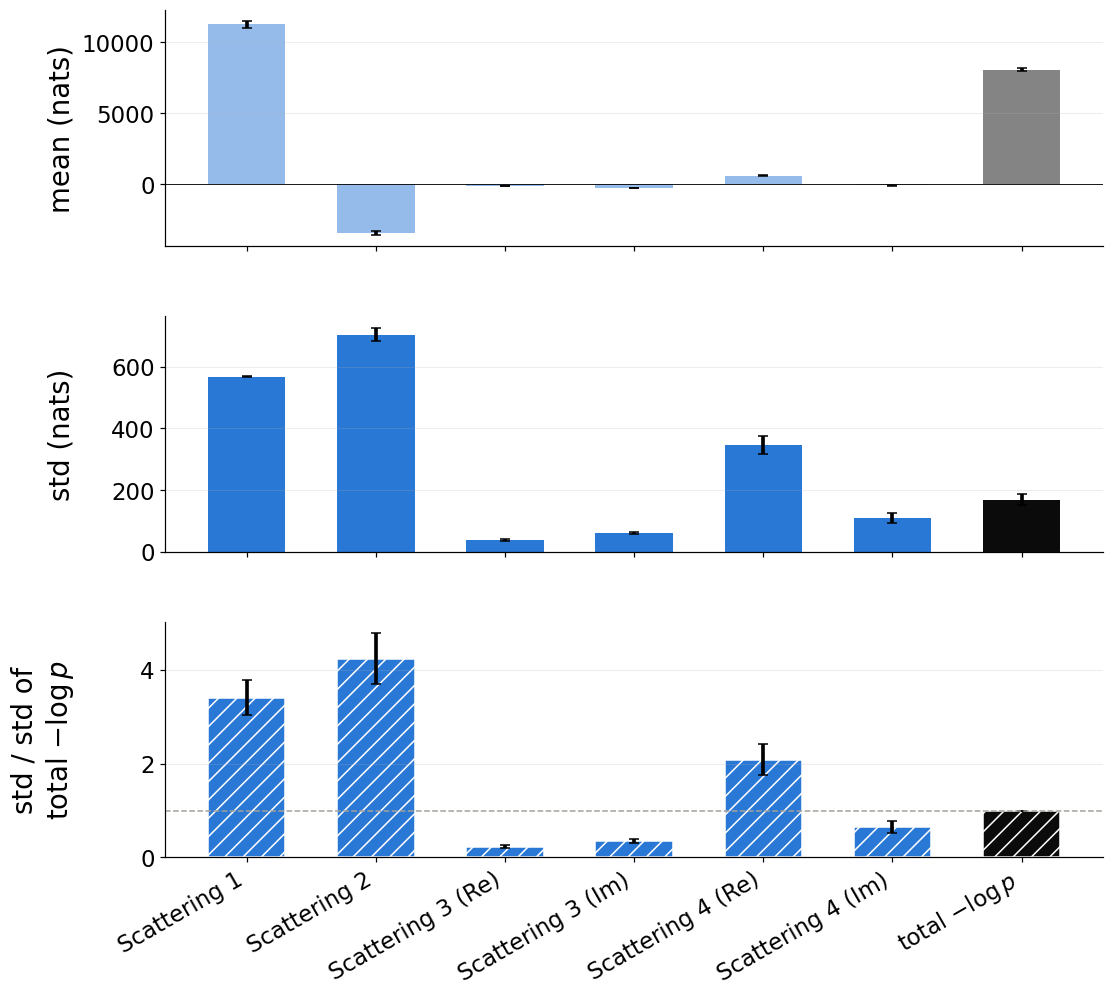

In [28]:
import re
fams = [str(f) for f in D['families']]
rank = lambda f: next(i for i, (pat, _) in enumerate(tf._LABELS) if re.search(pat, f))     # scalar, scat1, scat2, scat3 Re/Im, scat4 Re/Im
order = sorted(range(len(fams)), key=lambda i: rank(fams[i]))                              # the builder creates scat2 after scat3
tf.plot_energy_bars({**{fams[i]: Cg[:, i] for i in order}, 'TOTAL': Cg[:, -1]}, 'logp_per_family', Q=cfg['Q'])

## Number of statistics in the model

In [29]:
exp = rc._find_exp_dir(ROOT, configs[SEEDS[0]])
pots = load_potentials(exp, cfg, 'cpu')
n_stats = tf.count_statistics(pots, torch.as_tensor(x1[:, None, :]).float(), theta, Q=cfg['Q'])
n_stats.to_csv(ROOT / 'figures' / 'talk' / 'number_of_statistics.csv')
display(n_stats)

,statistics,with Θ ≠ 0 at t = 1
family,,
Scattering 1,6,6
Scattering 3 (Re),27,27
Scattering 3 (Im),21,21
Scattering 2,7,7
Scattering 4 (Re),56,56
Scattering 4 (Im),20,20
total,137,137


## Table: first-order KL per dimension of each category of statistics
Same definition as in talk_turbulence.ipynb: per category $k$, $\mathrm{Var}(\ln p_k)/(2d\ln 10)$ with $d = 6062$, in digits per dimension (the units of the $u=-\log_{10}p/d$ axis of the histogram), computed over the **generated** series (the data is a single series), mean $\pm$ std over the 5 seeds, each cell with its own power of ten. Shaded column (a different quantity): std$(-\log p)$, the std of the total $u$ over the series (width of the histogram). The categories do not add up (correlated contributions). No confinement term in this model. Saved as `kl_table_snp.csv`, read by talk_jets.ipynb for the overall table.

In [ ]:
fm = [str(x) for x in D['families']]
K_snp = tf.kl_table({k: D['C_gen'][:, i] for i, k in enumerate(fm)}, {k: int(w) for k, w in zip(fm, D['widths'])},
                    x1.shape[1], 'kl_table_snp')                      # d = 6062; D = logp_snp_M1.npz (loaded above)
display(K_snp)
tf.plot_kl_table_single(K_snp, 'kl_table_snp', 'S&P 500')

In [ ]:
# widths of -log10 p / d: three separate figures (neglogp_widths_1/2/3), same x and y limits
Dsnp = np.load(ROOT.parent / 'snp_experiment' / 'figures' / 'logp_snp' / 'logp_snp_M1.npz')
Gj = np.load(ROOT.parent / 'jets' / 'figures' / 'logp_jets' / 'logp_generated_jets_full.npz')
Gt = np.load(ROOT.parent / 'turbulence' / 'figures' / 'data' / 'talk_logp_generated_turbulence_nested_M3_bicw_allmass_scat4.npz')
tf.plot_logp_widths({'Eulerian (jets)': (-Gj['logp'], 256),               # d = M = 256 (both configs)
                     'Lagrangian (turbulence)': (-Gt['logp'], 256),
                     'S&P 500': (-Dsnp['C_gen'][:, -1], 6062)}, 'neglogp_widths')